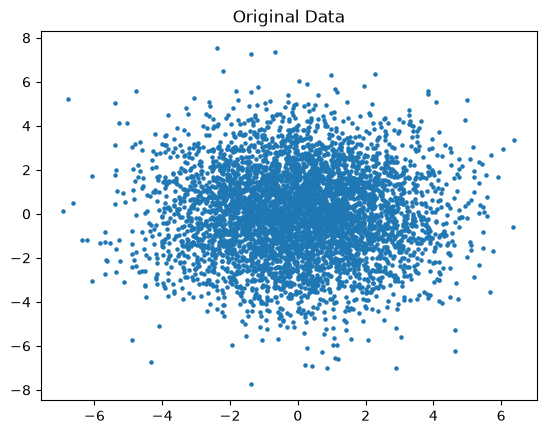

In [25]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

data = np.random.randn(5000, 2).astype("float32") * 2

plt.scatter(data[:, 0], data[:, 1], s=5)
plt.title("Original Data")
plt.show()

In [20]:
T = 50

beta = tf.linspace(0.001, 0.02, T)
alpha = 1 - beta
alpha_bar = tf.math.cumprod(alpha)

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(2)
])

model.compile(optimizer="adam", loss="mse")

In [22]:
for epoch in range(50):
    t = np.random.randint(0, T, len(data))
    noise = np.random.randn(*data.shape).astype("float32")

    ab = tf.gather(alpha_bar, t).numpy()[:, None]
    noisy_data = np.sqrt(ab) * data + np.sqrt(1 - ab) * noise

    inputs = np.concatenate(
        [noisy_data, (t / T).reshape(-1, 1)], axis=1
    )

    model.train_on_batch(inputs, noise)

print("Training complete!")

Training complete!


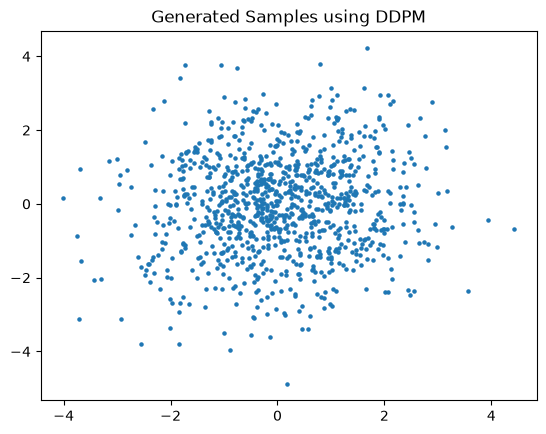

In [23]:
x = tf.random.normal((1000, 2))

for t in reversed(range(T)):
    time = tf.ones((1000, 1)) * (t / T)
    inputs = tf.concat([x, time], axis=1)

    predicted_noise = model(inputs, training=False)

    x = (x - beta[t] / tf.sqrt(1 - alpha_bar[t])
         * predicted_noise) / tf.sqrt(alpha[t])

    if t > 0:
        x += tf.sqrt(beta[t]) * tf.random.normal((1000, 2))

generated = x.numpy()

plt.scatter(generated[:, 0], generated[:, 1], s=5)
plt.title("Generated Samples using DDPM")
plt.show()